<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 10 · Uncertainty</p><p class="mh-facts"><span class="lvl lvl-advanced">Advanced</span></p><p class="mh-assumes">Assumes <a href="/blogs/quantile-regression/quantile_regression.html">Quantile regression</a> and <a href="/blogs/cross-validation/cross_validation.html">Cross-validation</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Conformal prediction puts an interval around any model that holds a stated share of new outcomes. Hold out a calibration set the model never saw, measure the model's error on each of its $n$ rows, and widen every new prediction by the $\lceil (n+1)(1-\alpha) \rceil$-th smallest error. If calibration rows and new rows are exchangeable, at least $1-\alpha$ of new outcomes land inside. On synthetic harvest data, boosted 10th and 90th percentile models held $71.1\%$ of new weeks; conformalised, $82.8\%$. The guarantee is an average over inputs: a constant-width interval covered $99.1\%$ of small weeks and $66.1\%$ of large ones while averaging $83.3\%$. Time series break exchangeability. After a synthetic change in a weekly series, intervals calibrated once covered $54.5\%$ of weeks; recalibrating on the last 52 weeks' errors gave $79.8\%$, and adaptive conformal inference, which adjusts $\alpha$ after every hit or miss, $82.5\%$. Afterwards you should be able to wrap a scikit-learn model in split conformal or conformalised quantile regression, check coverage by group, and calibrate each horizon on recent backtest errors.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import beta
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from threadpoolctl import threadpool_limits

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
threadpool_limits(1)  # thousands of small predictions run faster on one thread each
rng = np.random.default_rng(42)
ALPHA = 0.2  # allowed miss rate: 80% intervals, as in the quantile regression module

## A guarantee around any model

[Quantile regression](../quantile-regression/quantile_regression.ipynb) ended with boosted 10th and 90th percentile models holding $64.5\%$ of outcomes on unseen fields, against $80\%$ intended. Tuning moves coverage but cannot promise it. Conformal prediction, which comes from Vovk, Gammerman and colleagues[^1] and has a practical introduction by Angelopoulos and Bates[^2], can. Its simplest version, **split conformal prediction**, has three steps:

1. Fit the model on one part of the data; keep a second part, the **calibration set** of $n$ rows, out of fitting and model selection.
2. Score each calibration row by how wrong the model was, here $R_i = \lvert y_i - \hat{y}(x_i) \rvert$.
3. Widen each new prediction by the $k$-th smallest score, $d$:

$$\hat{C}(x) = \bigl[\hat{y}(x) - d,\ \hat{y}(x) + d\bigr], \qquad d = R_{(k)}, \qquad k = \lceil (n+1)(1-\alpha) \rceil$$

where $\hat{y}(x)$ is the model's prediction for input $x$, $y_i$ and $x_i$ are the outcome and input of calibration row $i$, $R_{(k)}$ is the $k$-th smallest of the $n$ scores, all in tonnes here, $\alpha$ is the allowed miss rate (dimensionless; $0.2$ for an 80% interval), and $\lceil \cdot \rceil$ rounds up.

Lei and colleagues prove that if the calibration rows and the new row are **exchangeable**, so that shuffling them would not change their joint distribution (independent draws are the usual case), the new outcome lands inside with probability at least $1 - \alpha$[^3]. The probability is over the new row *and* the calibration set: an average over the calibration sets you might have drawn. Like a validation fold in [Cross-validation](../cross-validation/cross_validation.ipynb) the calibration set must be unseen, but it is used once, after the model is chosen.

::: {.callout-note collapse="true"}
## Why $n+1$, and why it works

Add a new row's score, $R_{n+1} = \lvert y_{n+1} - \hat{y}(x_{n+1}) \rvert$, to the $n$ calibration scores. The model was fitted on other data and the score is the same function applied to each row, so if the $n + 1$ rows are exchangeable their scores are too, and the new score is equally likely to hold any of the $n + 1$ ranks (assume no ties). The new outcome is inside exactly when the new score ranks $k$-th or lower, which has probability $k/(n+1)$. Choosing $k = \lceil (n+1)(1-\alpha) \rceil$ makes that at least $1-\alpha$ and less than $1 - \alpha + 1/(n+1)$; counting the new row among the ranks is where $n + 1$ comes from.
:::

The data are the synthetic harvest weeks from Quantile regression, whose spread grows with area picked: 1,000 weeks fit a boosted mean model, 500 calibrate and 5,000 stand in for the future.

In [2]:
def conformal_quantile(scores, alpha=ALPHA):
    """The ceil((n + 1)(1 - alpha))-th smallest of n scores, or infinity if that rank is above n."""
    n = len(scores)
    # alpha >= 1 (reachable only in the adaptive update) returns the smallest score instead of
    # an empty interval: a simplification of that edge case.
    k = max(int(np.ceil((n + 1) * (1 - alpha))), 1)
    return np.inf if k > n else np.sort(scores)[k - 1]

In [3]:
def harvest(n):
    """Synthetic weeks, as in Quantile regression: tonnes = hectares x yield, yield ~ N(1.2, 0.3) t/ha."""
    ha = rng.uniform(5, 50, n)
    return ha[:, None], ha * rng.normal(1.2, 0.3, n)


X_fit, y_fit = harvest(1000)  # fits the model
X_cal, y_cal = harvest(500)  # calibrates the interval, never seen by the model
X_new, y_new = harvest(5000)  # stands in for future weeks

model = HistGradientBoostingRegressor(random_state=0).fit(X_fit, y_fit)
d = conformal_quantile(np.abs(y_cal - model.predict(X_cal)))
pred = model.predict(X_new)
inside_split = np.abs(y_new - pred) <= d
print(f"half-width d = {d:.2f} t; new weeks inside prediction ± d: {inside_split.mean():.1%}")

half-width d = 12.22 t; new weeks inside prediction ± d: 83.3%


The half-width is $12.22\text{ t}$, and $83.3\%$ of new weeks fall inside. On your data: with 1,500 labelled weeks, fit on the oldest 1,000 and calibrate on the next 500; with time-ordered data, calibrate on the most recent rows.

You get one calibration set, so the coverage you realise is one draw. Redrawing the set 1,000 times shows how far from $80\%$ that draw can sit:

In [4]:
# The same model, recalibrated on 1,000 fresh sets of 500 weeks, each scored on 2,000 fresh weeks.
coverage = []
for _ in range(1000):
    Xc, yc = harvest(500)
    Xt, yt = harvest(2000)
    dc = conformal_quantile(np.abs(yc - model.predict(Xc)))
    coverage.append(np.mean(np.abs(yt - model.predict(Xt)) <= dc))

print(f"simulated, n = 500: mean {np.mean(coverage):.2%}, 5th to 95th percentile "
      f"{np.percentile(coverage, 5):.1%} to {np.percentile(coverage, 95):.1%}")
for n in (500, 167):  # the Beta prediction for this set, and for a third of it
    l = int((n + 1) * ALPHA)
    print(f"Beta, n = {n}: 5th to 95th percentile {beta(n + 1 - l, l).ppf(0.05):.1%} to {beta(n + 1 - l, l).ppf(0.95):.1%}")

constant = DummyRegressor().fit(X_fit, y_fit)  # predicts the training mean for every week
dc = conformal_quantile(np.abs(y_cal - constant.predict(X_cal)))
print(f"constant model: half-width {dc:.1f} t, new weeks inside {np.mean(np.abs(y_new - constant.predict(X_new)) <= dc):.1%}")

simulated, n = 500: mean 80.06%, 5th to 95th percentile 76.9% to 83.3%
Beta, n = 500: 5th to 95th percentile 77.0% to 82.9%
Beta, n = 167: 5th to 95th percentile 75.1% to 85.2%
constant model: half-width 23.7 t, new weeks inside 82.7%


Coverage averages $80.06\%$, and 90% of sets give $76.9\%$ to $83.3\%$. A Beta distribution fixed by $n$ and $\alpha$ predicts nearly the same, $77.0\%$ to $82.9\%$; with a third as many rows, roughly $75\%$ to $85\%$.

The last line is what "any model" means: a constant model that ignores the hectares still covers $82.7\%$, with a half-width of $23.7\text{ t}$, almost twice the boosted model's. The model sets the width, not the validity. MAPIE and crepes package these methods for scikit-learn models; this module uses plain NumPy to show the mechanics.

## Right on average, wrong by group

Split conformal adds the same $d$ everywhere, too much for small blocks and too little for large. The guarantee survives because it is about **marginal coverage**, $P\bigl(Y \in \hat{C}(X)\bigr) \ge 1 - \alpha$ averaged over inputs, not **conditional coverage**, $P\bigl(Y \in \hat{C}(X) \mid X = x\bigr) \ge 1 - \alpha$ at every input value $x$, where $X$ and $Y$ are a new input and outcome. Lei and colleagues note that conditional coverage cannot be achieved without assumptions about the model and the data.

**Conformalised quantile regression** (CQR), from Romano, Patterson and Candès[^4], gets closer. It starts from a pair of quantile models, so the width can follow the input, and scores how far each calibration outcome falls outside them:

$$E_i = \max\bigl\{\hat{q}_\text{lo}(x_i) - y_i,\ y_i - \hat{q}_\text{hi}(x_i)\bigr\}, \qquad \hat{C}(x) = \bigl[\hat{q}_\text{lo}(x) - Q,\ \hat{q}_\text{hi}(x) + Q\bigr]$$

where $\hat{q}_\text{lo}$ and $\hat{q}_\text{hi}$ are the fitted 0.1 and 0.9 quantile models, $E_i$ is row $i$'s score (negative when inside), and $Q$ is the $k$-th smallest score, all in tonnes. A positive $Q$ widens both ends, a negative one narrows them; the guarantee is unchanged.

In [5]:
q_lo, q_hi = (
    HistGradientBoostingRegressor(loss="quantile", quantile=q, random_state=0).fit(X_fit, y_fit) for q in (0.1, 0.9)
)
lo, hi = np.sort([q_lo.predict(X_new), q_hi.predict(X_new)], axis=0)  # sorted, in case they cross
print(f"boosted 0.1 and 0.9 quantiles as fitted: {np.mean((y_new >= lo) & (y_new <= hi)):.1%} of new weeks inside")

lo_cal, hi_cal = np.sort([q_lo.predict(X_cal), q_hi.predict(X_cal)], axis=0)
Q = conformal_quantile(np.maximum(lo_cal - y_cal, y_cal - hi_cal))
inside_cqr = (y_new >= lo - Q) & (y_new <= hi + Q)
print(f"CQR: Q = {Q:.2f} t; new weeks inside [lo - Q, hi + Q]: {inside_cqr.mean():.1%}")

boosted 0.1 and 0.9 quantiles as fitted: 71.1% of new weeks inside
CQR: Q = 2.11 t; new weeks inside [lo - Q, hi + Q]: 82.8%


As fitted, the boosted pair holds $71.1\%$ of new weeks; CQR adds $Q = 2.11\text{ t}$ to each end and reaches $82.8\%$. The tables split coverage and width by area picked. The third column calibrates within each range on about a third of the calibration weeks, and a calibration that small is itself noisy: roughly $75\%$ to $85\%$, by the Beta range above.

In [6]:
labels = ["5-20 ha", "20-35 ha", "35-50 ha"]
group_cal, group_new = (pd.cut(X[:, 0], [5, 20, 35, 50], labels=labels, include_lowest=True) for X in (X_cal, X_new))
res_cal = np.abs(y_cal - model.predict(X_cal))
d_group = {g: conformal_quantile(res_cal[group_cal == g]) for g in labels}  # one calibration per group
d_new = np.array(group_new.map(d_group), dtype=float)
inside_group = np.abs(y_new - pred) <= d_new

inside = pd.DataFrame({"split": inside_split, "CQR": inside_cqr, "split by group": inside_group})
width = pd.DataFrame({"split": np.full(len(y_new), 2 * d), "CQR": hi - lo + 2 * Q, "split by group": 2 * d_new})


def by_group(table):
    out = table.groupby(group_new, observed=True).mean()
    out.loc["all"] = table.mean()
    return out


by_group(inside).round(3)  # share of new weeks inside each 80% interval

,split,CQR,split by group
5-20 ha,0.991,0.882,0.756
20-35 ha,0.835,0.832,0.835
35-50 ha,0.661,0.767,0.831
all,0.833,0.828,0.806


In [7]:
by_group(width).round(1)  # mean interval width (t)

,split,CQR,split by group
5-20 ha,24.4,13.1,9.3
20-35 ha,24.4,24.1,24.5
35-50 ha,24.4,30.9,37.2
all,24.4,22.5,23.3


Split conformal covers $99.1\%$ of 5–20 ha weeks and $66.1\%$ of 35–50 ha weeks. CQR's width follows the spread, $13.1$ to $30.9\text{ t}$, narrowing the gap to $88.2\%$ and $76.7\%$; its constant $Q$ still over-covers small weeks. Neither promises anything per group.

When a group matters, calibrate within it: rows within one range are still exchangeable, so each range gets its own guarantee (group-balanced conformal prediction, in Angelopoulos and Bates). Coverage becomes $75.6\%$, $83.5\%$ and $83.1\%$; the $75.6\%$ is within the noise of a calibration on a third of the rows, not a failure. Each group costs rows, so use few, broad groups.

## Time series break exchangeability

Next week depends on this week, which voids the proof, though coverage holds in the stable stretch below. Worse, the process changes, with a new packing line or variety, and last year's residuals then describe last year, as in [Backtesting properly](../backtesting/backtesting_properly.ipynb). Two fixes combine:

- **Calibrate on recent errors**: the last $K$ rolling-origin residuals at each origin, as Angelopoulos and Bates suggest for drifting data.
- **Adaptive conformal inference** (ACI), from Gibbs and Candès[^5], moves the level after each outcome:

$$\alpha_{t+1} = \alpha_t + \gamma\,(\alpha - \text{err}_t)$$

where $\alpha$ is the target miss rate ($0.2$), $\alpha_t$ the level used for week $t$'s interval (starting at $\alpha$), $\text{err}_t$ is 1 if week $t$'s outcome fell outside and 0 otherwise, and $\gamma > 0$ is a step size, all dimensionless. A miss widens the next interval; a hit narrows it a little. Gibbs and Candès prove the long-run miss rate converges to $\alpha$ whatever the data do, but not for any particular stretch of weeks. The step size trades speed for stability: they used $\gamma = 0.005$, this module $0.05$ for weekly data; choose it on a rolling coverage plot like Figure 1. After a run of misses $\alpha_t$ can reach 0, asking for an interval that covers everything; this module suggests capping the width at a planning maximum, or falling back to the rolling interval, and flagging the week.

The test is synthetic: six years of weekly volume shaped like [Leakage](../leakage/leakage.ipynb)'s, whose level rises $8\text{ t}$ and shock standard deviation from $4$ to $7\text{ t}$ at week 208, forecast one week ahead by a ridge model fitted on years 1–2. Three rules set the half-width in years 4–6: **static**, on year 3's errors; **rolling**, on the last 52 weeks' errors; **adaptive**, the rolling rule at level $\alpha_t$. Coverage is averaged over 200 histories:

In [8]:
N, SHIFT = 312, 208  # six years of weeks; the change arrives at the start of year 5


def weekly(seed):
    """Synthetic weekly volume (t) shaped as in Leakage; at week 208 level +8 t, shock SD 4 -> 7 t."""
    r = np.random.default_rng(seed)
    week = np.arange(N) % 52
    eps = np.zeros(N)
    for t in range(1, N):
        eps[t] = 0.6 * eps[t - 1] + r.normal(0, 4 if t < SHIFT else 7)
    return 40 + 25 * np.sin(2 * np.pi * (week - 13) / 52).clip(0) + 8 * (np.arange(N) >= SHIFT) + eps


def forecast(y):
    """One-week-ahead ridge forecast on last week's volume and the season, fitted once on years 1-2."""
    week = np.arange(N) % 52
    X = np.column_stack([np.r_[np.nan, y[:-1]], np.sin(2 * np.pi * week / 52), np.cos(2 * np.pi * week / 52)])
    model = Ridge().fit(X[1:104], y[1:104])
    return np.r_[np.nan, model.predict(X[1:])]

In [9]:
def half_widths(res, window=52, gamma=0.05):
    """Half-widths for weeks 156-311 under three calibration rules; res holds |actual - forecast|."""
    static = conformal_quantile(res[104:156])  # year 3's errors, used for ever after
    a = ALPHA
    rows = []
    for t in range(156, N):
        recent = res[t - window : t]  # the last 52 weeks' errors, all known by week t
        d_adaptive = conformal_quantile(recent, a)
        rows.append((static, conformal_quantile(recent), d_adaptive))
        a += gamma * (ALPHA - (res[t] > d_adaptive))  # adaptive update, once week t is observed
    return np.array(rows)


weeks = np.arange(156, N)
covered = []
for seed in range(200):
    y = weekly(seed)
    res = np.abs(y - forecast(y))
    covered.append(res[weeks, None] <= half_widths(res))
covered = np.array(covered)  # shape: (history, week, rule)

periods = {"year 4": weeks < SHIFT, "first 26 wk after": (weeks >= SHIFT) & (weeks < SHIFT + 26),
           "next 78 wk": weeks >= SHIFT + 26}
rules = ["static", "rolling 52 wk", "adaptive"]
pd.DataFrame({p: covered[:, m].mean(axis=(0, 1)) for p, m in periods.items()}, index=rules).round(3)

,year 4,first 26 wk after,next 78 wk
static,0.804,0.550,0.545
rolling 52 wk,0.806,0.623,0.798
adaptive,0.803,0.724,0.825


Before the change all three cover $80.3\%$ to $80.6\%$. After it, the static interval covers $55.0\%$, then $54.5\%$: nothing in it learns. The rolling interval recovers as new errors fill its window, $62.3\%$ in the first 26 weeks and $79.8\%$ after. The adaptive one widens within weeks, $72.4\%$ then $82.5\%$, running above target while it makes up for the misses of the transition.

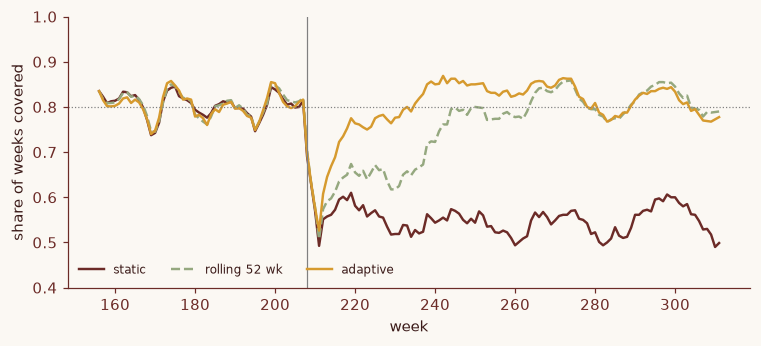

In [10]:
fig, ax = plt.subplots(figsize=(8, 3.2))
for j, c, ls in [(0, C3, "-"), (1, C4, "--"), (2, C2, "-")]:
    share = pd.Series(covered[:, :, j].mean(axis=0)).rolling(4, min_periods=1).mean()  # 4-week smoothing
    ax.plot(weeks, share, color=c, ls=ls, lw=1.6, label=rules[j])
ax.axhline(1 - ALPHA, color="0.5", lw=0.8, ls=":")
ax.axvline(SHIFT, color="0.5", lw=0.8)
ax.set(xlabel="week", ylabel="share of weeks covered", ylim=(0.4, 1))
ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower left")
plt.show()

<strong>Figure 1 | A calibration set from before a change stops covering after it.</strong> Share of weeks inside each rule's 80% interval, averaged over 200 synthetic histories and smoothed over 4 weeks. The change is at week 208 (vertical line); the dotted line is the 80% target.

**Per horizon.** In a pipeline the scores come from the backtest, one set per horizon. An $h$-week-ahead error is known only $h$ weeks after its origin, so at issue week $t$ the newest usable score is from origin $t - h$; Gibbs and Candès list delayed outcomes as a case their analysis does not cover. This function returns each horizon's half-width from the latest 52 errors known at issue time, shown on one synthetic history with a naive forecast (last week's volume):

In [11]:
def half_width_by_horizon(backtest, issue, n=52, alpha=ALPHA):
    """backtest: one row per (origin, horizon), sorted by origin, with actual and forecast."""
    known = backtest[backtest["origin"] + backtest["horizon"] <= issue]  # an h-step error arrives h weeks later
    err = (known["actual"] - known["forecast"]).abs()
    recent = err.groupby(known["horizon"]).tail(n)
    return recent.groupby(known["horizon"]).apply(lambda e: conformal_quantile(e.to_numpy(), alpha))


y = weekly(0)
rows = [(t, h, y[t + h], y[t]) for t in range(104, N - 1) for h in range(1, 5) if t + h < N]
backtest = pd.DataFrame(rows, columns=["origin", "horizon", "actual", "forecast"])  # forecast: naive, last week
half_width_by_horizon(backtest, issue=N - 1).round(1)  # half-width (t) for forecasts issued at week 311

horizon
1    10.2
2    14.7
3    17.7
4    17.0
dtype: float64

The half-width rises from $10.2\text{ t}$ one week ahead to $17.7$ and $17.0\text{ t}$ at three and four weeks. For horizon 4 the newest score comes from origin 307, four weeks before the issue week, 311.

## Key takeaways

- Calibrate on rows that played no part in fitting or choosing the model. A better model buys a narrower interval, not validity.
- Expect one calibration set to miss the target by a few points; size it, and any group in it, before calling a shortfall a failure.
- Check coverage where decisions are made. Use CQR when the spread follows the inputs, and calibrate within a group that needs its own guarantee.
- Conformalise quantile models rather than trust them.
- On a time series, calibrate each horizon on its latest backtest errors known at issue time, add ACI with a step size checked on a rolling coverage plot, and cap and flag infinite intervals.

## References

[^1]: Vovk, V., Gammerman, A. & Shafer, G. *Algorithmic Learning in a Random World* 2nd edn (Springer, 2022). https://doi.org/10.1007/978-3-031-06649-8
[^2]: Angelopoulos, A. N. & Bates, S. Conformal prediction: a gentle introduction. *Found. Trends Mach. Learn.* **16**, 494–591 (2023). https://doi.org/10.1561/2200000101
[^3]: Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R. J. & Wasserman, L. Distribution-free predictive inference for regression. *J. Am. Stat. Assoc.* **113**, 1094–1111 (2018). https://doi.org/10.1080/01621459.2017.1307116
[^4]: Romano, Y., Patterson, E. & Candès, E. Conformalized quantile regression. In *Advances in Neural Information Processing Systems 32* (NeurIPS, 2019). https://proceedings.neurips.cc/paper/2019/hash/5103c3584b063c431bd1268e9b5e76fb-Abstract.html
[^5]: Gibbs, I. & Candès, E. Adaptive conformal inference under distribution shift. In *Advances in Neural Information Processing Systems 34* (NeurIPS, 2021). https://proceedings.neurips.cc/paper/2021/hash/0d441de75945e5acbc865406fc9a2559-Abstract.html

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/quantile-regression/quantile_regression.html"><span>Previous</span>Quantile regression</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/hierarchical-reconciliation/hierarchical_reconciliation.html"><span>Next</span>Hierarchical reconciliation</a></div>
<!-- CURRICULUM_FOOTER_END -->